In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split

In [2]:
df = pd.read_csv('../data/processed/credit_risk_dataset_cleaned.csv')
#Load the cleaned credit risk dataset from the specified CSV file into a pandas DataFrame for further analysis and modeling.
df.shape
#Check the shape of the DataFrame to understand the number of rows and columns in the dataset.


(32409, 14)

In [3]:
y = df['loan_status']
#Define the target variable 'y' as the 'loan_status' column from the DataFrame
x = df.drop(columns=['loan_status'])
#Define the feature set 'x' by dropping the 'loan_status' column from the DataFrame, which will be used for model training and prediction.
x = pd.get_dummies(x, drop_first=True)
#Remove the redundant column from each category 
print(x.shape)
#Check the shape of the feature set 'x' to understand the number of rows and columns after encoding categorical variables using one-hot encoding with the 'drop_first' parameter set to True, which avoids multicollinearity by dropping the first category of each categorical variable.

(32409, 24)


The data has been splot into two parts, 'y' and 'x'. 'y' is 'loan_status, the target the model will try to predict. 'x' is every other column with the information used to make the prediction. 

Here, the data has been prepped for modelling. 
The target variable 'y' is 'loan_status' (1 = default, 0 = no default), which is what the model will learn to predict. The feature set 'x' contains the other columns. 

Some columns were converted into numeric 0/1 columns using one-hot encoding because scikit-learn models can only work with numbers. 'drop_first=true' removes one redundant column per category, since it can be worked out from the others. 

In [4]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)
#Split the dataset into training and testing sets using an 80-20 split, with a random state of 42 for reproducibility and stratification based on the target variable 'y' to ensure that the class distribution is maintained in both the training and testing sets.
print(x_train.shape, x_test.shape)
print(y_train.mean(), y_test.mean())
#Confirm the sizes of the training and testing sets, as well as the mean of the target variable in both sets to ensure that the stratification was successful and that the class distribution is similar in both sets.

(25927, 24) (6482, 24)
0.21869093994677363 0.218759642085776


Stratification was used to split the dataset into training and testing sets

Both sets have the same default rate (21.87% in training and 21.88% in testing), suggesting that stratification worked. 

The data was split 80/20 into a training set (25,927) loans and a test set of (6482). The split is stratified on loan_status so both sets keep the same default rate. 

In [5]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import classification_report, accuracy_score
#Import the DummyClassifier from scikit-learn to create a baseline model for comparison, and import the classification_report and accuracy_score functions to evaluate the performance of the model.

In [6]:
baseline = DummyClassifier(strategy='most_frequent')
#Create a baseline model using the DummyClassifier with the strategy set to 'most_frequent', which predicts the most frequent class in the training data for all instances. This serves as a simple benchmark to compare against more complex models.
baseline.fit(x_train, y_train)
#Train the baseline model on the training data (x_train and y_train) to learn the most frequent class in the target variable.
baseline_pred = baseline.predict(x_test)
#Make predictions on the test set (x_test) using the trained baseline model and store the predicted values in the variable 'baseline_pred'.
print('Baseline Accuracy:', accuracy_score(y_test, baseline_pred))
#Accuracy score of the baseline model on the test set, which indicates the proportion of correct predictions made by the model. This serves as a reference point for evaluating the performance of more complex models.
print(classification_report(y_test, baseline_pred, zero_division=0))

Baseline Accuracy: 0.781240357914224
              precision    recall  f1-score   support

           0       0.78      1.00      0.88      5064
           1       0.00      0.00      0.00      1418

    accuracy                           0.78      6482
   macro avg       0.39      0.50      0.44      6482
weighted avg       0.61      0.78      0.69      6482




- Support shows how many loans in the test really belong to that class 
- Precision asks "when the model says default, how often is it right?"
- Recall asks "of the loans that really defaulted, how many did the model catch?"
- F1-score is a number that combines precision and recall. It is high only when both are reasonably high. 

About 78% of the loans do not default. 
The report has one row for each class, 0 (no default) and 1 (default) and the columns score how well the model did on each one. 
- Class (0) - Precision 0.78 shows 78% of the loans it called no default were really fine and recall 1.00 shows it caught every default 
- Class (1) - Precision, recall and F1 are all 0.00. It never said default, meaning it didn't catch any of the real 1418 defaulters. 
Missing a defaulter in credit risk is a costly mistake so class 1 recall is important to watch closely. 

In [7]:
from sklearn.ensemble import RandomForestClassifier
# Initialize the Random Forest Classifier

In [8]:
fr_model = RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=42)
#Create an instance of the RandomForestClassifier with 200 trees, balanced class weights to handle class imbalance, and a random state of 42 for reproducibility.
fr_model.fit(x_train, y_train)
fr_model_pred = fr_model.predict(x_test)
#Train the Random Forest model on the training data and make predictions on the test set.
print('Random Forest Accuracy:', accuracy_score(y_test, fr_model_pred))
print(classification_report(y_test, fr_model_pred))

Random Forest Accuracy: 0.9273372415921012
              precision    recall  f1-score   support

           0       0.94      0.97      0.95      5064
           1       0.88      0.77      0.82      1418

    accuracy                           0.93      6482
   macro avg       0.91      0.87      0.89      6482
weighted avg       0.93      0.93      0.93      6482



A random forest classifier (200 trees, 'class weight='balanced'') was trained on all 24 features 

The model caught defaulter whereas the basline caught none

- Precision in class 1 was rigth 88% of the time when it flagged a loan. 
- Recall in class 1 caught 77% of the 1418 real defaulters, meaning it missed 33%.
- Accuracy is up to 93% from the baseline.


What comes next tests whether the model still beats the basline without including the loan_grade and loan_int_rate

In [9]:
cols_to_drop = [c for c in x_train.columns if c.startswith("loan_grade")] + ["loan_int_rate", "int_rate_missing"]
#Identify columns to drop from the feature set based on specific criteria, such as those starting with "loan_grade" and the columns "loan_int_rate" and "int_rate_missing", which may be redundant or not useful for the model.
x_train_no = x_train.drop(columns=cols_to_drop)
x_test_no = x_test.drop(columns=cols_to_drop)
#Drop the identified columns from both the training and testing feature sets to create new datasets (x_train_no and x_test_no) that exclude these columns, potentially improving model performance by removing irrelevant or redundant features.
print(x_train_no.shape)

(25927, 16)


6 loan_grade columns have removed, grades B to G (A was removed earlier), as well as loan_int_rate and int_rate_missing. 

In [10]:
fr_model_no = RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=42)
#Train a new Random Forest model on the modified training set (x_train_no) that excludes the identified columns, and make predictions on the modified test set (x_test_no).
fr_model_no.fit(x_train_no, y_train)
fr_model_no_pred = fr_model_no.predict(x_test_no)   
#Predict the target variable on the modified test set using the newly trained Random Forest model.
print('Random Forest (Without Loan Grade and Interest Rate) Accuracy:', accuracy_score(y_test, fr_model_no_pred))
print(classification_report(y_test, fr_model_no_pred))

Random Forest (Without Loan Grade and Interest Rate) Accuracy: 0.8739586547361925
              precision    recall  f1-score   support

           0       0.90      0.94      0.92      5064
           1       0.76      0.62      0.68      1418

    accuracy                           0.87      6482
   macro avg       0.83      0.78      0.80      6482
weighted avg       0.87      0.87      0.87      6482



A random forest was trained with 'loan_grade', 'loan_int_rate' and int_rate_missing removed as grade and interest rate are assigned by the lender and have their own risk assessment. 

This model reached 87% accuracy and for the default class, a precision of 0.76, recall of 0.62 and F1-score of 0.68 compared to 0.00 for the baseline. Recall drops to 0.62 from 0.77 and F1 dropsto 0.68 from 0.82 showing that the loan grade and interest rate carry useful information about risk. 

## Classification Summary
- Both random forests clearly outprform the baseline, which never identified a defualter. 
- The full model perfromed the best, showing that loan grade and interest rate are useful information 
- Yet a model built on borrower and loan characteristics still identifies a majority of defaulters 
- The limitation of the models are that they are based from a single train/test split. 


## Clustering

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
#import clustering and scaling libaries

In [12]:
df = pd.read_csv('../data/processed/credit_risk_dataset_cleaned.csv')
df.shape

(32409, 14)

In [13]:
cluster_features = ['person_income', 'loan_amnt', 'loan_int_rate', 'loan_percent_income', 'person_emp_length', 'cb_person_cred_hist_length']
cluster_data = df[cluster_features].copy()
#Select specific features from the original DataFrame (df) that are relevant for clustering analysis and create a new DataFrame (cluster_data) containing only these selected features. The chosen features include 'person_income', 'loan_amnt', 'loan_int_rate', 'loan_percent_income', 'person_emp_length', and 'cb_person_cred_hist_length', which are likely to provide meaningful insights into the underlying patterns in the data for clustering purposes.

cluster_data['person_income'] = np.log1p(cluster_data['person_income'])
#Income is often right-skewed, so we apply a log transformation to the 'person_income' feature in the cluster_data DataFrame using the np.log1p function. This transformation helps to reduce skewness and stabilize variance, making the data more suitable for clustering algorithms that assume normally distributed features.



In [14]:
print(cluster_features)
#Display the list of features selected for clustering analysis 

['person_income', 'loan_amnt', 'loan_int_rate', 'loan_percent_income', 'person_emp_length', 'cb_person_cred_hist_length']


In [15]:
scaler = StandardScaler()
scaled = scaler.fit_transform(cluster_data)
#Scale the selected features in the cluster_data DataFrame using the StandardScaler from scikit-learn. This standardization process transforms the features to have a mean of 0 and a standard deviation of 1, which is important for clustering algorithms that are sensitive to the scale of the input data.

## Data is prepeared for clustering 

- Six features describing the borrower and their loan were selected for clustering ('person_income', 'loan_amnt', 'loan_int_rate', 'loan_percent_income', 'person_emp_length', 'cb_person_cred_hist_length')
- loan_status was deliberately left out so the segments are formed from the borrower and loan characterstics alone. 
- person_income is highly right-skewed as a small number of borrowers earn very high incomes, hence why a log tranformation was applied to reduce its influence, allowing the typical incomes to carry more weight than the few outliers. 

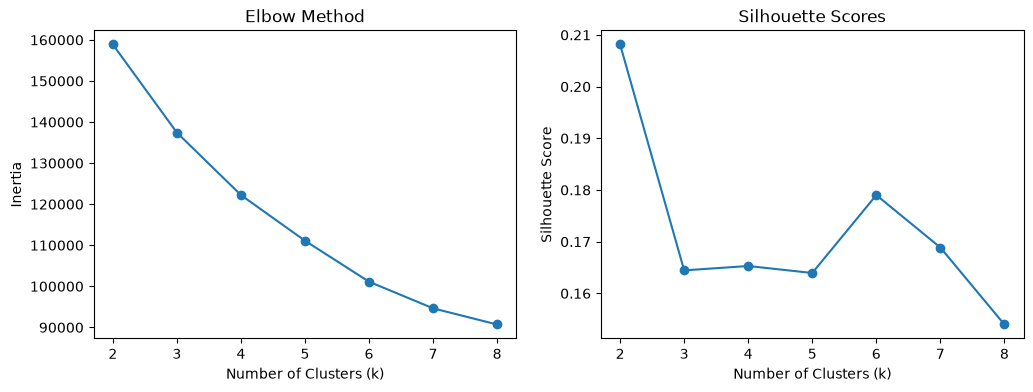

In [16]:
intertias = []
#Initialize an empty list called 'intertias' to store the inertia values for different numbers
silhouette_scores = []
k_values = range(2, 9)
#Iterate over a range of k values (from 2 to 8) and record how well it fits. 
for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(scaled)
    intertias.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(scaled, labels, sample_size=5000, random_state=42))
    #silhouette_score is a measure of how similar an object is to its own cluster compared to other clusters. A higher silhouette score indicates that the object is well matched to its own cluster and poorly matched to neighboring clusters. The silhouette score ranges from -1 to 1, where a value close to 1 indicates that the object is well clustered, a value close to 0 indicates that the object is on or very close to the decision boundary between two neighboring clusters, and a value close to -1 indicates that the object may have been assigned to the wrong cluster.

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
#Plot the inertia and silhouette scores for different values of k to visualize the performance of the KMeans clustering algorithm. The left subplot shows the inertia values, which represent the sum of squared distances between data points and their assigned cluster centers. The right subplot shows the silhouette scores, which indicate how well-separated the clusters are. By analyzing these plots, we can determine the optimal number of clusters (k) for our dataset based on the "elbow" method and silhouette analysis.

axes[0].plot(k_values, intertias, marker='o')
axes[0].set_title('Elbow Method')
axes[0].set_xlabel('Number of Clusters (k)')
axes[0].set_ylabel('Inertia')
#Left chart shows the inertia values for different numbers of clusters (k) using the elbow method. The x-axis represents the number of clusters, while the y-axis represents the inertia values. The plot helps to identify the optimal number of clusters by looking for the "elbow" point where the inertia starts to decrease at a slower rate.

axes[1].plot(k_values, silhouette_scores, marker='o')
axes[1].set_title('Silhouette Scores')
axes[1].set_xlabel('Number of Clusters (k)')
axes[1].set_ylabel('Silhouette Score')
#Right chart shows the silhouette scores for different numbers of clusters (k). The x-axis represents the number of clusters, while the y-axis represents the silhouette scores. The plot helps to assess the quality of clustering by indicating how well-separated the clusters are. A higher silhouette score suggests better-defined clusters.

plt.show()


## The Silhouette and Elbow chart

- The elbow plot shows a smooth decline in inertia with no clear elbow
- Silhouette scores are low across all values of k between 0.15 and 0.21, indicating how the clusters overlap with no clear seperated groups. 
- k=2 scored the highest, k=3, 4, and 5 scored almost identically and k=6 had a small gain, k=8 the groups are too small. 
- K=4 is chosen as a balance and is explored further in the next model

In [17]:
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
#Build the KMeans clustering model with 4 clusters
df_clustered = df.copy()
#Create a copy of the original DataFrame (df) to store the clustering results without modifying the original data. This allows for further analysis and visualization of the clustered data while preserving the original dataset for reference or additional processing.
df_clustered["cluster"] = kmeans.fit_predict(scaled)


In [18]:
profile = df_clustered.groupby("cluster").agg(
    loans=('loan_status', 'count'),
    default_rate_pct=('loan_status', lambda s: s.mean() * 100),
    avg_income=('person_income', 'mean'),
    avg_loan_amnt=('loan_amnt', 'mean'),
    avg_int_rate=('loan_int_rate', 'mean'),
    avg_loan_pct_income=('loan_percent_income', 'mean'),
    avg_emp_length=('person_emp_length', 'mean'),
    avg_cred_hist=('cb_person_cred_hist_length', 'mean')
#profile each cluster using the original values so numbers are easy to read 
).round(2)

print(profile) 

         loans  default_rate_pct  avg_income  avg_loan_amnt  avg_int_rate  \
cluster                                                                     
0         9084             37.01    33284.39        6749.20         12.04   
1         6327             34.72    81529.98       19382.40         12.35   
2         4914             12.66    85099.42        8802.02         10.78   
3        12084              7.51    74411.91        6925.48          9.64   

         avg_loan_pct_income  avg_emp_length  avg_cred_hist  
cluster                                                      
0                       0.21            2.88           4.91  
1                       0.28            5.01           5.38  
2                       0.13            9.19          11.83  
3                       0.10            4.25           4.26  


Kmeans with 4 clusters was combined with 6 borrower and loan features without loan_status. The default rate for each cluster differs largely, showing that the clusters seperate risk, supporting the choice of k=4. 

Cluster (0) and (1) are the two highest risk segments, with almost 50% of borrowers and around 78% of defaults. Additionally, silhouette scores were low, so the segments overlap.

Cluster (1) borrowers have high incomes, but still default often as their loans are large compared with their income, highlighting how income alone does not make a borrower safe. 

Next, the segments will be named and the clusters will be saved. 

In [19]:
segment_names = {
    0: 'Low-income, short-history',
    1: 'Large-loan, high-burden',
    2: 'Established, experienced',
    3: 'Conservative, low-risk'
    }
#Name the clusters based on previous profile table 
df_clustered['segment'] = df_clustered['cluster'].map(segment_names)
#Add segment name as new column
print(df_clustered.groupby('segment')['loan_status'].agg(['count', 'mean']))
#Check that names were applied 

                           count      mean
segment                                   
Conservative, low-risk     12084  0.075058
Established, experienced    4914  0.126577
Large-loan, high-burden     6327  0.347242
Low-income, short-history   9084  0.370101


In [20]:
df_clustered.to_csv('../data/processed/cred_risk_clustered.csv', index=False)
print('Saved:', df_clustered.shape)


Saved: (32409, 16)
